# Lab 4 — Notebook 1: Weak Labeling of IMDb Reviews

**Author:** Kshitij Maurya

**Goal:** label movie reviews as **positive** or **negative** *without hand-labeling them*, by writing simple rules (labeling functions) and combining their votes.

IMDb reviews come with true labels, which is handy: we hide them while labeling, then use them to measure how good our weak labels really are.

```
[Notebook 1: Weak Labeling] -> Notebook 2: Augmentation -> Notebook 3: Model Development
```

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

LAB_ROOT = Path.cwd().parent          # notebooks/ -> Lab4/
sys.path.insert(0, str(LAB_ROOT))

from src.config import load_config, lab_path
from src.data_validator import DataValidator
from src import utils

cfg = load_config()
FIG_DIR = lab_path(cfg["model"]["figures_dir"])
POS, NEG, ABSTAIN = cfg["labeling"]["positive"], cfg["labeling"]["negative"], cfg["labeling"]["abstain"]
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

### Step 1 — Load the reviews and run data checks
The dataset is an 8,000-review sample of the IMDb 50K Movie Reviews dataset (`review`, `sentiment`).

In [2]:
df = utils.load_reviews(lab_path(cfg["data"]["raw"]))

validator = DataValidator(required_columns=["review", "sentiment"], min_rows=1000,
                          text_col="review", label_col="sentiment")
validator.run(df)
validator.print_report()
df.head(3)

Loaded imdb_reviews.csv: 8,000 rows, 2 columns
Data validation: PASSED
  [ok] enough rows          8,000 rows (need 1,000)
  [ok] required columns     all present
  [ok] no missing values    0 missing cells
  [ok] no duplicate rows    0 duplicates
  [ok] text long enough     0 texts under 3 words
  [ok] class balance        negative: 50.0%, positive: 50.0%


,review,sentiment
0,Oh my goodness. This was a real big mess that just couldn't help itself. Jeffrey (Jon Heder) is a 29 year old man st...,negative
1,"There are no flaws in this production. Perfectly entertaining, fun, and worthy of respect.<br /><br />This is what t...",positive
2,"I thought that this movie was pretty lame. If you're looking for cheesey, you may like this. I, myself, don't mind a...",negative


### Step 2 — Clean the text and explore it
Reviews contain HTML line breaks (`<br />`). We strip them, lowercase everything, and count words.

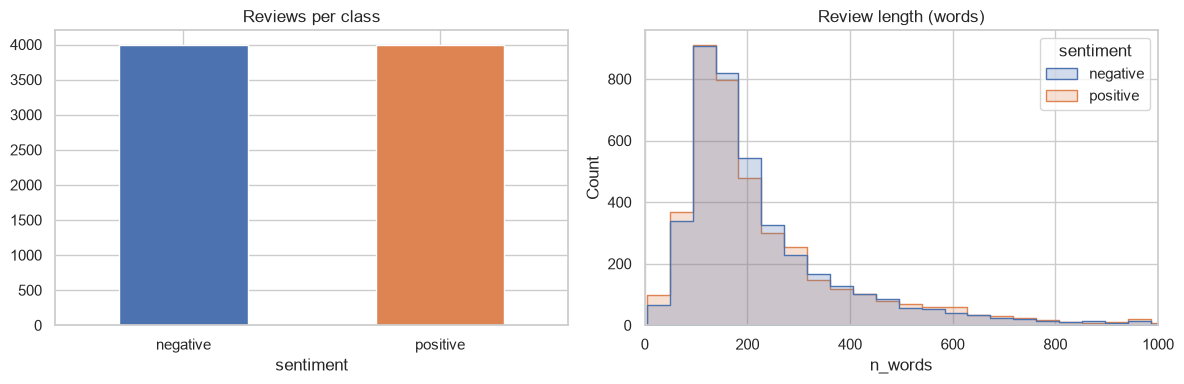

In [3]:
df["text"] = df["review"].apply(utils.clean_review)
df["n_words"] = df["text"].apply(utils.word_count)
df["gold"] = df["sentiment"].map({"positive": POS, "negative": NEG})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["sentiment"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"], rot=0)
axes[0].set_title("Reviews per class")
sns.histplot(data=df, x="n_words", hue="sentiment", bins=50, ax=axes[1], element="step")
axes[1].set_xlim(0, 1000)
axes[1].set_title("Review length (words)")
plt.tight_layout()
utils.save_fig(fig, FIG_DIR / "01_eda.png")
fig

In [4]:
# Most common words in each class — a first hint for which keywords might make good rules
top_pos = utils.top_words(df.loc[df["sentiment"] == "positive", "text"], n=15)
top_neg = utils.top_words(df.loc[df["sentiment"] == "negative", "text"], n=15)
pd.concat([top_pos.add_prefix("positive_"), top_neg.add_prefix("negative_")], axis=1)

,positive_word,positive_count,negative_word,negative_count
0,not,4506,not,5291
1,like,2879,like,3654
2,it's,2696,out,2956
3,out,2634,it's,2736
4,very,2608,even,2481
5,more,2393,bad,2391
6,good,2374,good,2312
7,great,2093,would,2144
8,time,2085,more,2120
9,story,2021,really,2063


### Step 3 — Keep a gold test set aside
In a real labeling project the training data has **no labels**. To mimic that, we split off 20% of the reviews as a test set (true labels kept for the final evaluation in Notebook 3) and treat the remaining 80% as unlabeled.

In [5]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=cfg["split"]["test_size"],
                               stratify=df["gold"], random_state=cfg["split"]["random_state"])
train, test = train.reset_index(drop=True), test.reset_index(drop=True)

utils.save_csv(test[["text", "gold"]], lab_path(cfg["data"]["test_gold"]))
print(f"Unlabeled training pool: {len(train):,} | gold test set: {len(test):,}")

Saved 1,600 rows -> imdb_test_gold.csv
Unlabeled training pool: 6,400 | gold test set: 1,600


### Step 4 — Write the labeling functions (LFs)
Each LF looks at one review and votes `1` (positive), `0` (negative) or `-1` (abstain = "I don't know").

| LF | Rule | Vote |
|----|------|------|
| `lf_positive_words` | strong praise words (*masterpiece, superb …*) | positive |
| `lf_negative_words` | strong criticism words (*worst, waste of …*) | negative |
| `lf_recommend` | *highly recommend, must see …* | positive |
| `lf_avoid` | *don't waste, avoid this, not worth …* | negative |
| `lf_high_rating` | reviewer score `x/10` ≥ 7 | positive |
| `lf_low_rating` | reviewer score `x/10` ≤ 4 | negative |
| `lf_negated_praise` | *not good, not funny, not that great …* | negative |

The keyword lists live in `config.yaml`, so they can be tuned without editing code.

In [6]:
import re

lab = cfg["labeling"]
NEGATED_PRAISE = re.compile(r"\b(?:not|never)\s+(?:very\s+|that\s+|even\s+)?(?:good|great|funny|interesting|scary)\b")

def lf_positive_words(text):
    return POS if utils.contains_any(text, lab["positive_words"]) else ABSTAIN

def lf_negative_words(text):
    return NEG if utils.contains_any(text, lab["negative_words"]) else ABSTAIN

def lf_recommend(text):
    return POS if utils.contains_any(text, lab["recommend_words"]) else ABSTAIN

def lf_avoid(text):
    return NEG if utils.contains_any(text, lab["avoid_words"]) else ABSTAIN

def lf_high_rating(text):
    score = utils.extract_rating(text)
    return POS if score is not None and score >= lab["rating_high"] else ABSTAIN

def lf_low_rating(text):
    score = utils.extract_rating(text)
    return NEG if score is not None and score <= lab["rating_low"] else ABSTAIN

def lf_negated_praise(text):
    return NEG if NEGATED_PRAISE.search(text) else ABSTAIN

LFS = [lf_positive_words, lf_negative_words, lf_recommend, lf_avoid,
       lf_high_rating, lf_low_rating, lf_negated_praise]

# quick sanity check on made-up sentences
for s in ["a true masterpiece, 9/10", "the worst film ever. 2/10", "it was not that funny", "an average film"]:
    print(f"{s!r:40} -> {[lf(s) for lf in LFS]}")

'a true masterpiece, 9/10'               -> [1, -1, -1, -1, 1, -1, -1]
'the worst film ever. 2/10'              -> [-1, 0, -1, -1, -1, 0, -1]
'it was not that funny'                  -> [-1, -1, -1, -1, -1, -1, 0]
'an average film'                        -> [-1, -1, -1, -1, -1, -1, -1]


### Step 5 — Apply every LF to every review
The result is a **label matrix**: one row per review, one column per LF.

In [7]:
L = pd.DataFrame({lf.__name__: train["text"].apply(lf) for lf in LFS})
L.head()

,lf_positive_words,lf_negative_words,lf_recommend,lf_avoid,lf_high_rating,lf_low_rating,lf_negated_praise
0,-1,-1,-1,-1,1,-1,-1
1,-1,-1,-1,-1,-1,-1,-1
2,1,-1,-1,-1,-1,-1,-1
3,1,-1,-1,-1,-1,-1,-1
4,-1,-1,-1,-1,-1,-1,-1


### Step 6 — How good are the LFs?
* **coverage** — share of reviews an LF votes on
* **conflict** — share of reviews where LFs disagree
* **accuracy** — share of an LF's votes that match the true label (possible here only because IMDb has true labels; in a real project you would hand-label a small sample for this)

In [8]:
votes = L.to_numpy()
voted = votes != ABSTAIN
n_votes = voted.sum(axis=1)
has_pos, has_neg = (votes == POS).any(axis=1), (votes == NEG).any(axis=1)

print(f"Coverage: {(n_votes > 0).mean():.1%} of reviews got at least one vote")
print(f"Overlap:  {(n_votes > 1).mean():.1%} got two or more votes")
print(f"Conflict: {(has_pos & has_neg).mean():.1%} got both positive and negative votes")

gold = train["gold"].to_numpy()
lf_stats = pd.DataFrame({
    "coverage": voted.mean(axis=0),
    "votes": voted.sum(axis=0),
    "accuracy": [(votes[voted[:, j], j] == gold[voted[:, j]]).mean() for j in range(len(LFS))],
}, index=L.columns).sort_values("coverage", ascending=False)
lf_stats.round(3)

Coverage: 52.5% of reviews got at least one vote
Overlap:  11.8% got two or more votes
Conflict: 4.9% got both positive and negative votes


,coverage,votes,accuracy
lf_negative_words,0.264,1692,0.830
lf_positive_words,0.208,1332,0.801
lf_high_rating,0.048,307,0.945
lf_avoid,0.040,257,0.879
lf_low_rating,0.036,231,0.987
lf_recommend,0.034,217,0.880
lf_negated_praise,0.028,179,0.771


### Step 7 — Combine the votes with a majority vote
For each review we count positive and negative votes; the larger side wins. Reviews with no votes or a tie stay **abstained** and are dropped from the training set.

In [9]:
n_pos, n_neg = (votes == POS).sum(axis=1), (votes == NEG).sum(axis=1)
train["weak_label"] = np.select([n_pos > n_neg, n_neg > n_pos], [POS, NEG], default=ABSTAIN)

print(train["weak_label"].value_counts().rename({POS: "positive", NEG: "negative", ABSTAIN: "abstain"}))

labeled = train[train["weak_label"] != ABSTAIN]
print(f"\nLabeled {len(labeled):,} of {len(train):,} reviews ({len(labeled) / len(train):.1%})")
print(f"Weak-label accuracy vs true labels: {(labeled['weak_label'] == labeled['gold']).mean():.1%}")

weak_label
abstain     3286
negative    1745
positive    1369
Name: count, dtype: int64

Labeled 3,114 of 6,400 reviews (48.7%)
Weak-label accuracy vs true labels: 88.8%


### Step 8 — Look at some examples
Two reviews per class, plus two the rules got wrong — reading mistakes is the best way to improve the LFs.

In [10]:
cols = ["text", "weak_label", "gold"]
display(labeled[labeled["weak_label"] == POS].sample(2, random_state=1)[cols])
display(labeled[labeled["weak_label"] == NEG].sample(2, random_state=1)[cols])
print("Mistakes:")
display(labeled[labeled["weak_label"] != labeled["gold"]].sample(2, random_state=1)[cols])

,text,weak_label,gold
4177,"don't torture a duckling is one of fulci's earlier (and honestly, in terms of story-line, better...) films - and alt...",1,1
5174,this is arguably john thaw's finest performance where he successfully shakes off any traits of his inspector morse c...,1,1


,text,weak_label,gold
3594,"incredibly muddled, off-putting and ultimately ludicrous (""the horses, oh my god, the horses!"") thriller. it's creep...",0,0
5729,"celia johnson is good as the nurse. michael hordern is good as capulet, though it's his usual neighing and whinnying...",0,0


Mistakes:


,text,weak_label,gold
1817,from a poorly contrived plot line that makes almost no sense to bad dialogue and disjointed scenes to the ultimate d...,1,0
3571,i've given up trying to figure out what version of this i'm watching. the copyright at the end indicates 1983. and t...,1,0


### Step 9 — Save the weakly labeled training set
Only the text, its length and the weak label are saved — the true labels of the training pool are **not** passed on, so Notebook 3 trains purely on weak labels.

In [11]:
out = labeled[["text", "n_words", "weak_label"]].reset_index(drop=True)
DataValidator(required_columns=["text", "weak_label"], text_col="text", label_col="weak_label").run(out)
utils.save_csv(out, lab_path(cfg["data"]["weak_labeled"]))

Saved 3,114 rows -> imdb_weak_labeled.csv


### Step 10 — Coverage vs. accuracy chart
A good LF is either very accurate or covers many reviews — ideally both.

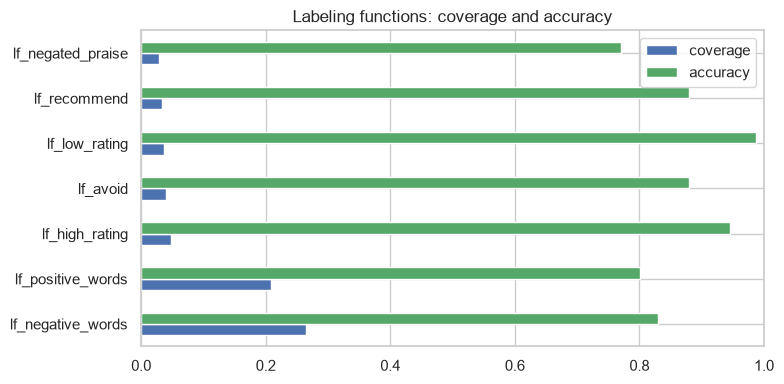

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
lf_stats[["coverage", "accuracy"]].plot(kind="barh", ax=ax, color=["#4C72B0", "#55A868"])
ax.set_xlim(0, 1)
ax.set_title("Labeling functions: coverage and accuracy")
plt.tight_layout()
utils.save_fig(fig, FIG_DIR / "01_lf_quality.png")
fig